## to do:

QoL
- plot nodes at any level of transform, see all_nodes
- automatically perform max. level transform
- plot single node by path
- time [s] instead of coefficient number
- automatically perform nodes2data on inverse
- fix plots

studentship:
- sensitivity analysis
- testing/tuning thresholding values (classification without machine learning)
- check out tree diagram
- sounds like a report. manuscript should be concise.
- explain the problem you're trying to address in the intro. as well as physics (materials and methods.)
- trying to find a quantitative relationship between cavitation and physical effects.
- write about alternative methods to analyse pcd data
- create filter diagram for wpt in intro, explaining the naming conventions for the levels, node number, coefficient number, etc.
- add entropy and other features that we will use. 
- write up feature selection
- use the silhouette score to test k-means with different numbers of clusters with different types of signals.
- find fundamental papers that I used for feature selection and clustering. (send them)
- generate dynamics data

algorithm
- stick with minimum entropy, find good filter (db order). implement algorithm that does this.
- test with different number of cycles.
- test normalised energy
- use tree graph to make filter bank diagram.

general coding:
- adaptive algorithm

writing:
- write about k-means
- add stuff to the literature review about the other works.

numerical results section:
- stable, stable with weak transients, fully transient (doesn't occur in practice)
- add noise to each
- might be able to do something with the database

latest
- talk about starting points in k-means
- maximum 12 pages
- minimum level of decomposition
- change colours of the flowchart
- change order of wavelet until clustering doesn't improve (find paper)
- write up the results using one stable and one transient signal
- test with pcd data
- conclusion
-  
- plotly?

to do
- define PCA
- save figures as ps or pdf
- make a table specifying which parameters were used to solve the gilmore-akulichev model.
- use (j, k) notation.
- overlay graphs and spectrums
- plot bar charts for the cluster centres.
- k-means 3d feature space plots
- report k-means parameters, look at how sensitive the algorithm is to each

done
- use smaller fontsize for algorithm, change algorithm to the simpler one without the diamond.
- move pcd data intro to start of methods. merge with existing description of features we expect to find in the signal
- change color and size of nodes in tree graph depending on the label of the node
- include fft of the reconstructions to show which features have been selected
- make a figure with nodes and classification
- define what kind of noise was added. additive white gaussian noise to simulate measurement noise. $20\log{\frac{\mu}{\sigma_{noise}}}=10$ signal to noise ratio

SOMs
- don't use numbers e.g. 2 dimensions, 3 clusters.
- cite classical reference for self-organising maps
- explain signals used for feature selection. choose wider frequency range, something that reflects the real life uses of ultrasound. go from 0.5 to 2 MHz.
- talk about variations on the neural network. refer to paper that uses som's to do feature selection.
- convergence analysis on self-organising maps with starting points, number of signals. see which are the best features in each case.
- decide whether to use SOMs

write-up
- don't start (conclusion not summary) with overall
- american english
- use a consistent tense (usually past)
- use commands
- use feature names instead of cluster number
- look at kurtosis to separate measurement noise from broadband

# Decompose a signal to its components at different frequency bands with WPT

In this notebook we aim to test WPT for extracting different components of a signal based on the energy, kurtosis, and crest factor of different frequency bands. The WPT library requires python3.6+ version. The following cell checks this requirement.

In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

Import the wavelet_transform package and required libraries.

In [ ]:
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.utils import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.utils.statistical_features as stats
from wavelet_transform.utils.extensions import fft as ext_fft

# matplotlib.use('nbagg')
import matplotlib.pyplot as plt
import numpy as np
import pywt
import scipy.stats as sc

Specify the parameters for generating a synthetic signal and to perform wavelet packet transform.

In [3]:
# keep the same
sampling_rate = 100  # unit: Hz

# PARAMETERS TO CHANGE
amplitudes = [1, 0.8, 0.4]  # amplitude of each sine wave
frequencies = [5, 15, 25]  # frequency content of signal
phases = [0, np.deg2rad(45), np.deg2rad(120)]  # phase of each sine wave

duration = 1000 / min(frequencies)  # duration of wave

trans_amp = [10 for _ in range(5)]  # amplitudes of transients
n_trans = len(trans_amp)  # number of transients
trans_dur = [0.05 for _ in range(n_trans)]  # duration of transients
trans_time = [
    duration * i / (n_trans + 1) for i in range(1, n_trans + 1)
]  # times of transients

std_noise = 0.1

wavelet = "db20"
levels = 5
mode = "symmetric"

sort_by = 'energy'  # 'energy', 'kurtosis', 'crest', 'False' -> freq
sort = "rec"  # 'rec' (reconstructed signal) 'coef' (transform coefficients)
n_highest = 3

fft_lim = 50  # increase value to view more of the fft plots

Generate synthetic multitonal signal with/without additive noise. We will fft the signal to double check the frequency contents.

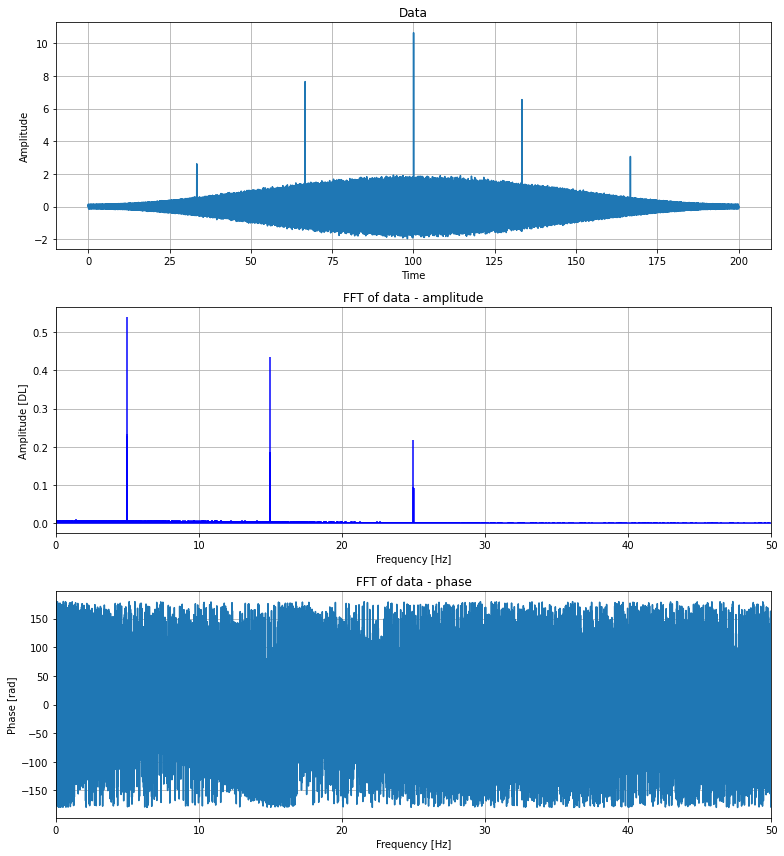

In [4]:
# generate sound wave
data, t_plot = sd.sound_wave(amplitudes, frequencies, phases, duration, sampling_rate)
signal_length = len(data)
data += sd.transients(trans_amp, trans_time, trans_dur, duration, sampling_rate)
data += sd.noise(std_noise,duration,sampling_rate)
data *= np.hamming(signal_length)

fft_data, freq = ext_fft(data, sampling_rate)
# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].stem(
    freq,
    np.abs(fft_data),
    linefmt="b",
    markerfmt=" ",
    basefmt="-b",
    use_line_collection=True,
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [DL]")
ax[1].set_xlim(0, sampling_rate / 2)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, sampling_rate / 2)
ax[2].grid()
fig.tight_layout()
plt.show()

### Frequency content of reconstructed subbands
Decompose signal using discrete wavelet packet transform and sort the nodes in order of energy, kurtosis, or crest factor.

functions used for sorting

In [5]:
def sort_nodes(rec, sort="rec", sort_by="energy"):
    """
    choose how to sort the subbands

    Parameters
    ----------
    rec: tuple
        tuple containing (coefficients,reconstructed_wave,fft_of_rec_wave,energy,kurtosis,crest)
    sort: str
        sort by 'energy', 'kurtosis', or 'crest' factor
    coef_or_rec: str
        sort by calculating attributes of the node coefficients or the reconstructed wave

    returns
    -------
    rec: tuple
        sorted input
    """
    if sort == "rec":
        if sort_by == "energy": 
            return sorted(rec, key=lambda x: x[3], reverse=True)
        elif sort_by == "kurtosis":
            return sorted(rec, key=lambda x: x[4], reverse=True)
        elif sort_by == "crest":
            return sorted(rec, key=lambda x: x[4], reverse=True)
            


    elif sort == "coef":
        if sort_by == "energy":
            return sorted(rec, key=lambda x: x[0].energy, reverse=True)
        if sort_by == "kurtosis":
            return sorted(rec, key=lambda x: x[0].kurtosis, reverse=True)
        if sort_by == "crest":
            return sorted(rec, key=lambda x: x[0].crest_factor, reverse=True)

Transform and sort nodes

In [6]:
# WPT transform
tr_obj = wpt.dwpt(data, levels, wavelet, mode)
tr_obj.calc_frequencies(sampling_rate)

# reconstruct each node separately
rec = []

for node in tr_obj.get_level(order="freq"):
    inverse = inv.inv_dwpt(tr_obj, nodes=node)
    inverse_signal_length = len(inverse)
    fft = ext_fft(inverse)
    energy = stats.energy(inverse)
    kurtosis = sc.kurtosis(inverse)
    crest = stats.crest_factor(inverse)
    entropy = stats.entropy(inverse)
    rec.append((node, inverse, fft, energy, kurtosis, crest, entropy))

plot the **`n_highest`** energy components (subbands).

In [7]:
def plot_reconstructions(rec, n_highest=None, group=None):
    partial_rec = np.zeros(signal_length)  # track sum of highest energy subbands
    if n_highest is None:
        n_highest = len(rec)
    for i, rec in enumerate(rec[:n_highest]):  # highest energy, kurtosis, etc.
        node, rec_wave, fft, energy, kurtosis, crest, entropy = rec
        partial_rec += rec_wave  # full reconstruction
        fig, ax = plt.subplots(
            2, figsize=(11, 8)
        )  # plot reconstructed wave and its fft
        freq_r = node.frequency_range
        ax[0].plot(t_plot, rec_wave)
        title = f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz]"
        if group is not None:
            title = f"Reconstructed subband [{freq_r[0]}- {freq_r[1]} Hz] group: {group[i]}"
        ax[0].set_title(title)
        ax[0].set_xlabel("time")
        ax[0].set_ylabel("amplitude")
        ax[1].stem(
            freq,
            np.abs(fft),
            linefmt="b",
            markerfmt=" ",
            basefmt="-b",
            use_line_collection=True,
        )
        ax[1].set_title("FFT of reconstructed subband")
        ax[1].set_xlabel("Frequency")
        ax[1].set_ylabel("Power")
        ax[1].set_xlim(
            max(0, freq_r[0] - fft_lim), min(sampling_rate / 2, freq_r[1] + fft_lim)
        )
        ax[1].grid()
        fig.tight_layout()
        plt.show()

        # print info
        print(f"energy of recovered signal: {energy}")
        print(f"kurtosis of recovered signal: {kurtosis}")
        print(f"crest factor of recovered signal: {crest}")
        print(f"entropy of recovered signal: {entropy}")
        print()
        print(f"energy of node coefficients: {node.energy}")
        print(f"kurtosis of node coefficients: {node.kurtosis}")
        print(f"crest factor of node coefficients: {node.crest_factor}")
        print(f"entropy of node coefficinets: {node.entropy}")
    return partial_rec

run = False
if run is True:
    # sort reconstructed waves
    sorted_rec = sort_nodes(rec, sort, sort_by)
    print(f"sorted by: {sort_by} of {sort}")
    # plot highest energy subbands
    partial_rec = plot_reconstructions(sorted_rec,n_highest)

### heisenberg visualisation

Making an heisenberg plot of the last level of dwpt

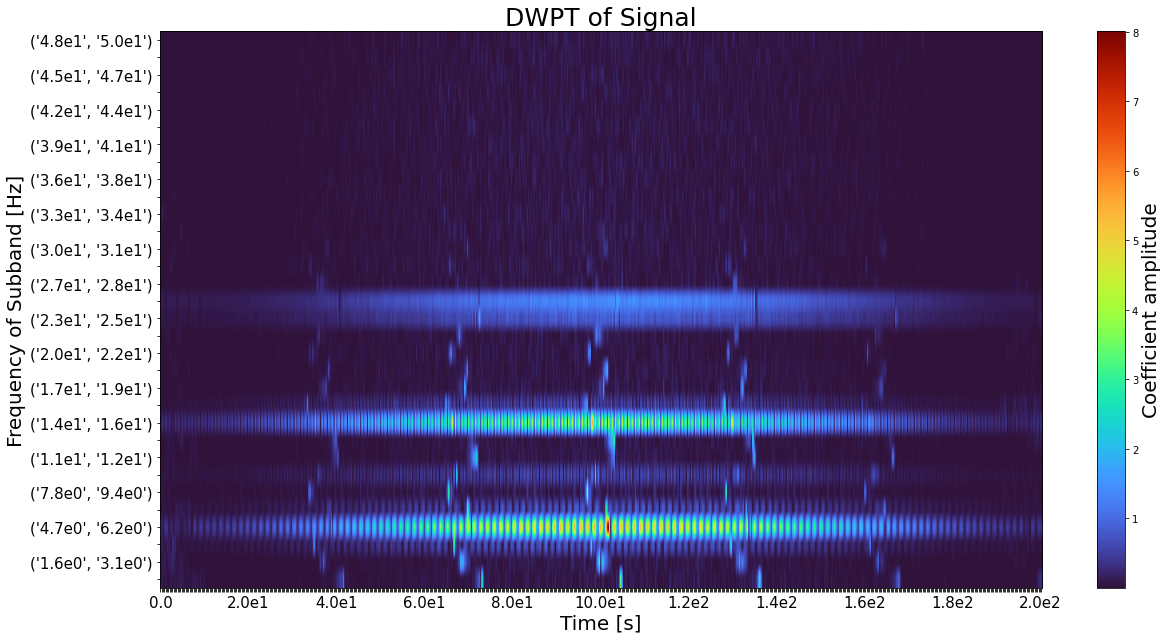

In [8]:
plot.heisenberg(tr_obj, max(t_plot))

### Clustering

k-means clustering algorithm with energy, kurtosis, and crest factor as the input

In [9]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# training data
data_train = []
for node, inverse, _, energy, kurtosis, crest, entropy in rec:
    data_train.append(
        (energy, kurtosis, crest, entropy)
        )

scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# training k-means algorithm
no_clusters = 5
kmeans = KMeans(n_clusters=no_clusters)
kmeans.fit(data_train_normalised)

# get labels and clusters
labels = kmeans.labels_
centers = scaler.inverse_transform(kmeans.cluster_centers_)

### plot result

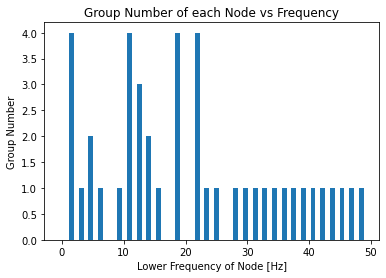

Cluster labels: [0 4 1 2 1 0 1 4 3 2 1 0 4 0 4 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
highest energy: 2
highest kurtosis: 3
highest crest factor: 3


In [10]:
# plot regular k-means
plt.bar([node.frequency_range[0] for node,*_ in rec], labels)
plt.title('Group Number of each Node vs Frequency')
plt.xlabel('Lower Frequency of Node [Hz]')
plt.ylabel('Group Number')
plt.show()

print("Cluster labels:", labels)
print(f"highest energy: {np.argmax(centers[:,0])}")
print(f'highest kurtosis: {np.argmax(centers[:,1])}')
print(f'highest crest factor: {np.argmax(centers[:,2])}')

### PCA

In [11]:
# apply PCA to training data
pca = PCA(n_components=3)
data_pca = pca.fit_transform(data_train_normalised)

# training k-means algorithm on the reduced data
kmeans_pca = KMeans(n_clusters=no_clusters)
kmeans_pca.fit(data_pca)

labels_pca = kmeans_pca.labels_
centers_pca = scaler.inverse_transform(pca.inverse_transform(kmeans_pca.cluster_centers_))

### Plot PCA Result

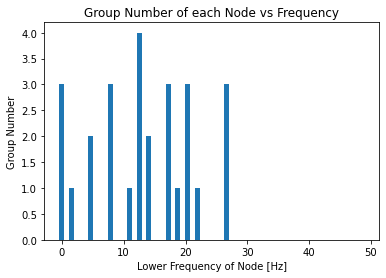

Eigenvectors:
Energy, Kurtosis, Crest factor, Peak, Mean
[[-0.21  0.56  0.57 -0.57]
 [ 0.98  0.19  0.08 -0.09]
 [-0.06  0.61 -0.77 -0.14]]
Eigenvalues: [3.05 0.95 0.07]
Cluster labels: [3 1 0 2 0 3 0 1 4 2 0 3 1 3 1 0 0 3 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
highest PC1: 2
highest PC2: 4
highest PC3: 4


In [12]:
# plot pca k-means
lower_freqs = [node.frequency_range[0] for node,*_ in rec]
plt.bar([node.frequency_range[0] for node,*_ in rec], labels_pca)
plt.tick_params
plt.title('Group Number of each Node vs Frequency')
plt.xlabel('Lower Frequency of Node [Hz]')
plt.ylabel('Group Number')
plt.show()

eigenvectors = pca.components_
eigenvalues = pca.explained_variance_

print("Eigenvectors:")
print('Energy, Kurtosis, Crest factor, Peak, Mean')
print(np.round(eigenvectors,2))

print("Eigenvalues:", np.round(eigenvalues,2))

print("Cluster labels:", labels_pca)
print(f"highest PC1: {np.argmax(centers_pca[:,0])}")
print(f'highest PC2: {np.argmax(centers_pca[:,1])}')
print(f'highest PC3: {np.argmax(centers_pca[:,2])}')

### 3d plot

3d plots of the results with axes energy, kurtosis, crest factor

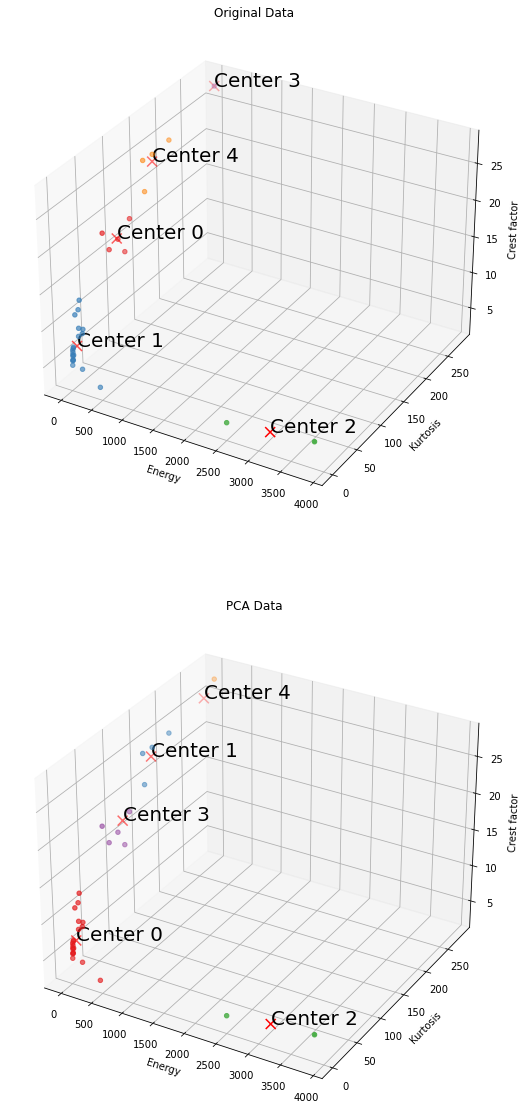

In [13]:
fig, ax = plt.subplots(2, figsize=(20, 20), subplot_kw={'projection': '3d'})

titles = ['Original Data', 'PCA Data']

# plot subplots for PCA data and non-PCA data
for i, ax in enumerate(ax):
    cmap = plt.cm.get_cmap('Set1')
    if i == 0:
        data_scatter = data_train
        centers_scatter = centers
        labels_scatter = labels
    else:
        data_scatter = data_train
        centers_scatter = centers_pca
        labels_scatter = labels_pca

    ax.scatter(
        [point[0] for point in data_scatter],
        [point[1] for point in data_scatter],
        [point[2] for point in data_scatter],
        c=[cmap(label) for label in labels_scatter])
    ax.scatter(
        centers_scatter[:, 0],
        centers_scatter[:, 1],
        centers_scatter[:, 2],
        c='red', marker='x', s=100)
    
    ax.set_xlabel('Energy')
    ax.set_ylabel('Kurtosis')
    ax.set_zlabel('Crest factor')
    ax.set_title(titles[i])

    # Annotate cluster centers with their positions
    for i, center in enumerate(centers_scatter):
        ax.text(center[0], center[1], center[2], f'Center {i}', color='black', fontsize=20)

plt.show()

### 2d plot

plots with energy vs crest factor comparing PCA and no PCA results

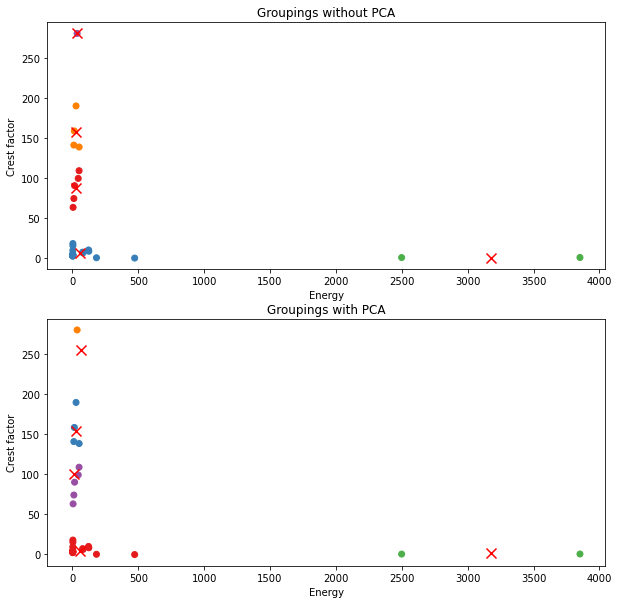

In [14]:
# 3d plot
fig, ax = plt.subplots(2,figsize=(10,10))

# plot with colours for each cluster
cmap = plt.cm.get_cmap('Set1')
x = 0  # 0 -> energy, 1 -> kurtosis, 3 -> crest
y = 1  # ""
data_scatter = data_train
labels_scatter = labels
ax[0].scatter(
    [point[x] for point in data_scatter],
    [point[y] for point in data_scatter],
    c=[cmap(label) for label in labels_scatter]
)
labels_scatter = labels_pca
ax[1].scatter(
    [point[x] for point in data_scatter],
    [point[y] for point in data_scatter],
    c=[cmap(label) for label in labels_scatter]
)
# plot centres
centers_scatter = centers
ax[0].scatter(centers_scatter[:, x], 
           centers_scatter[:, y], c='red', marker='x', s=100)
centers_scatter = centers_pca
ax[1].scatter(centers_scatter[:, x], 
           centers_scatter[:, y], c='red', marker='x', s=100)
for i in range(2):
    ax[i].set_xlabel('Energy')
    ax[i].set_ylabel('Crest factor')
ax[0].set_title('Groupings without PCA')
ax[1].set_title('Groupings with PCA')
plt.show()

### Results

Plotting the reconstructed waves from clustering with their assigned group

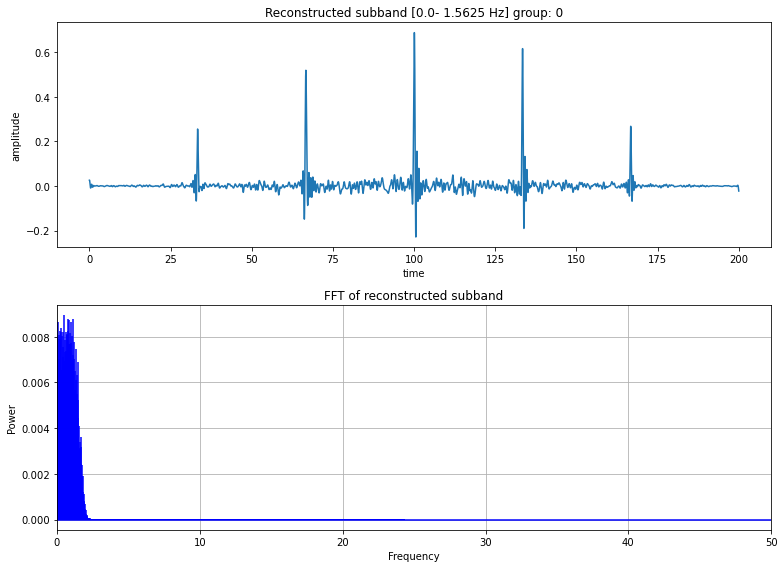

energy of recovered signal: 44.11497403565132
kurtosis of recovered signal: 99.01841545168074
crest factor of recovered signal: 14.642654487371756
entropy of recovered signal: 5.951855595617609

energy of node coefficients: 44.6371583706883
kurtosis of node coefficients: 101.15026912488345
crest factor of node coefficients: 14.101999731757413
entropy of node coefficinets: 2.659791256973861


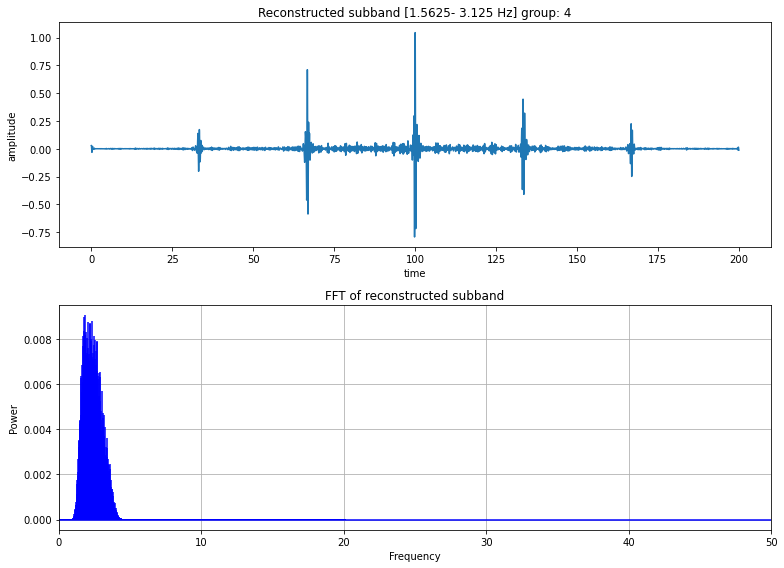

energy of recovered signal: 51.16723097987062
kurtosis of recovered signal: 138.23277114396743
crest factor of recovered signal: 20.673033458337116
entropy of recovered signal: 5.814263109217242

energy of node coefficients: 51.47154250238655
kurtosis of node coefficients: 49.71200918961221
crest factor of node coefficients: 11.34330081606265
entropy of node coefficinets: 3.254838544123742


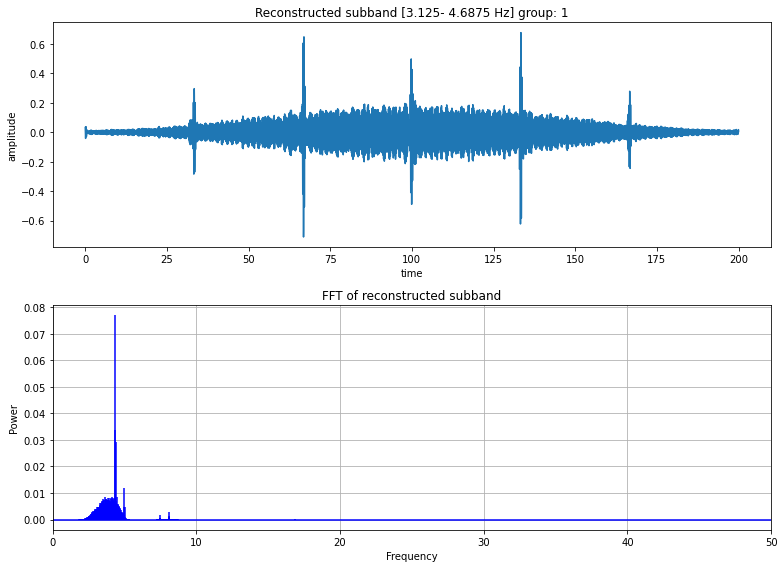

energy of recovered signal: 124.7308323973362
kurtosis of recovered signal: 7.955716817837214
crest factor of recovered signal: 9.007754829352097
entropy of recovered signal: 8.63770607032086

energy of node coefficients: 125.07294718271528
kurtosis of node coefficients: 12.377413849548065
crest factor of node coefficients: 7.947426742316877
entropy of node coefficinets: 5.147963912053606


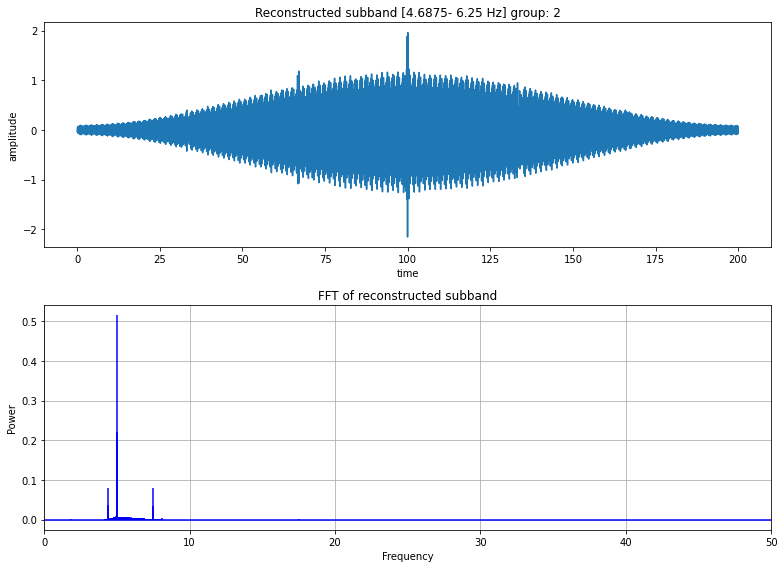

energy of recovered signal: 3852.2237231783447
kurtosis of recovered signal: 0.14436043301040247
crest factor of recovered signal: 4.913454402255756
entropy of recovered signal: 9.071800377461264

energy of node coefficients: 3854.4568705575816
kurtosis of node coefficients: 3.0521052016144226
crest factor of node coefficients: 3.3187212475253407
entropy of node coefficinets: 5.65716689832481


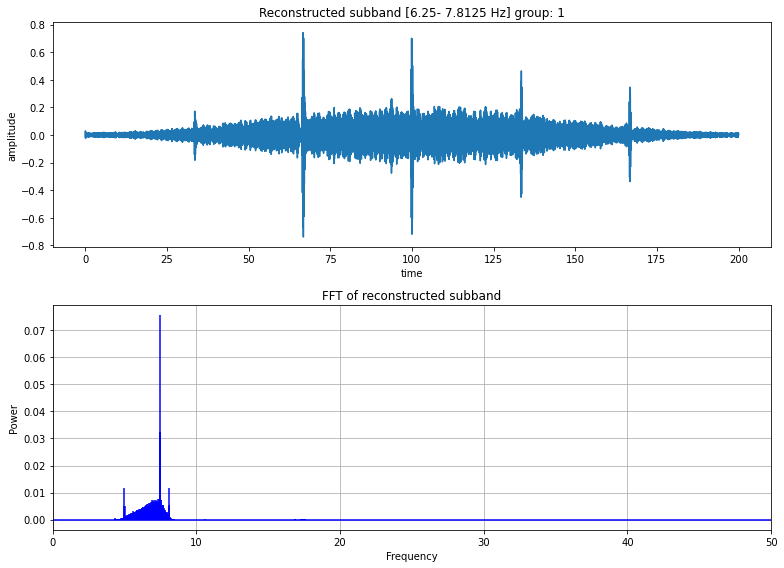

energy of recovered signal: 122.4275484205869
kurtosis of recovered signal: 9.58401586717165
crest factor of recovered signal: 9.48363039963809
entropy of recovered signal: 8.588797560390212

energy of node coefficients: 122.62315235106803
kurtosis of node coefficients: 10.693548393510593
crest factor of node coefficients: 7.0916603045223034
entropy of node coefficinets: 5.220799077956468


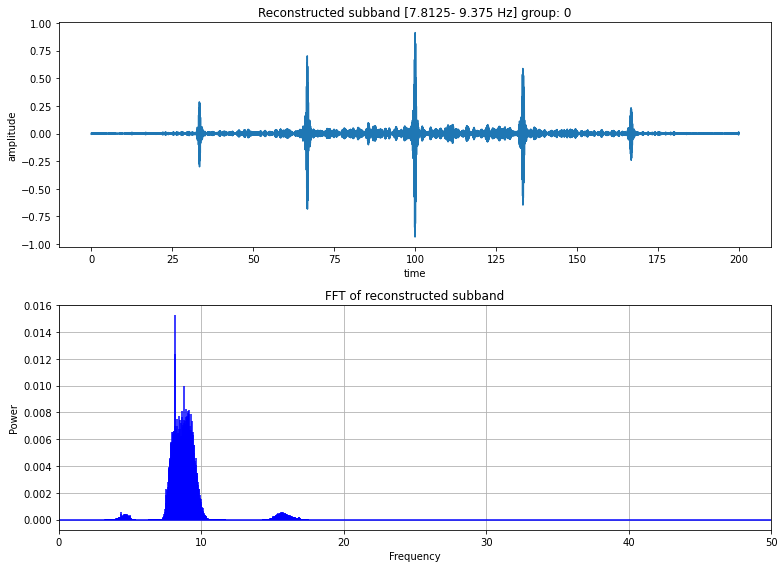

energy of recovered signal: 50.49835644740921
kurtosis of recovered signal: 108.63681893777911
crest factor of recovered signal: 18.628861079996014
entropy of recovered signal: 6.1607276932473685

energy of node coefficients: 50.535185238266685
kurtosis of node coefficients: 124.30370282697855
crest factor of node coefficients: 14.878639427996276
entropy of node coefficinets: 2.5770829257735577


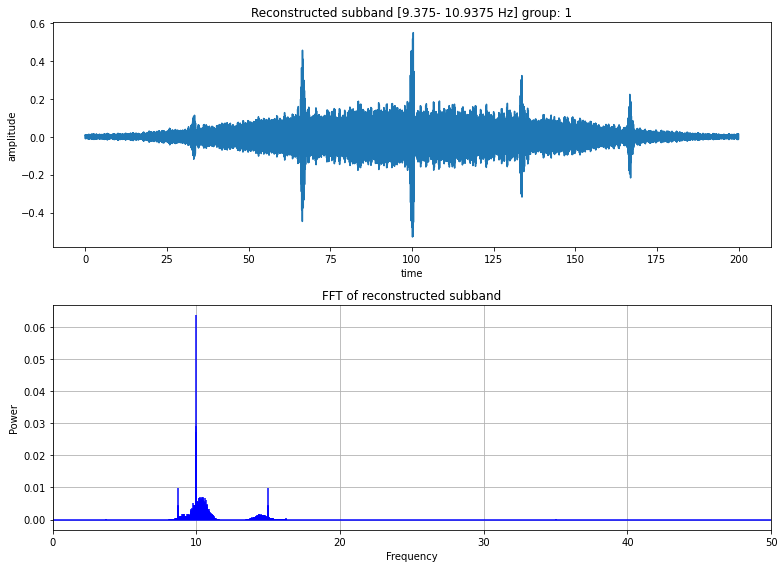

energy of recovered signal: 80.57819429040838
kurtosis of recovered signal: 5.8594225687849395
crest factor of recovered signal: 8.640649245478386
entropy of recovered signal: 8.690105358278865

energy of node coefficients: 80.67549417738097
kurtosis of node coefficients: 11.28640437594872
crest factor of node coefficients: 7.729362136691448
entropy of node coefficinets: 5.234714179328225


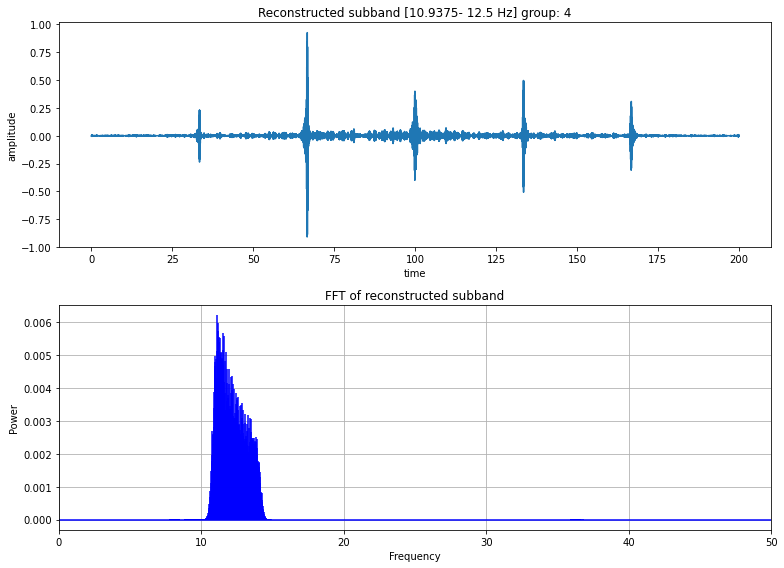

energy of recovered signal: 27.702132268892637
kurtosis of recovered signal: 189.60179513557497
crest factor of recovered signal: 24.87880308816776
entropy of recovered signal: 5.760171847684689

energy of node coefficients: 27.759135635173177
kurtosis of node coefficients: 66.16990884880937
crest factor of node coefficients: 12.479064018355828
entropy of node coefficinets: 3.048965438278173


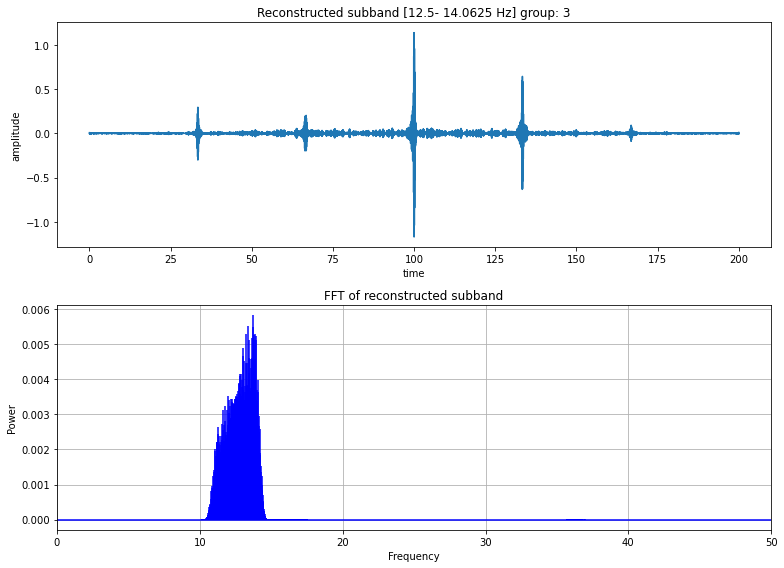

energy of recovered signal: 35.87142728949879
kurtosis of recovered signal: 280.22868058896483
crest factor of recovered signal: 27.62917405226105
entropy of recovered signal: 5.288243226524816

energy of node coefficients: 36.04226366711458
kurtosis of node coefficients: 103.4064697831664
crest factor of node coefficients: 14.432762953931258
entropy of node coefficinets: 2.6859571695570175


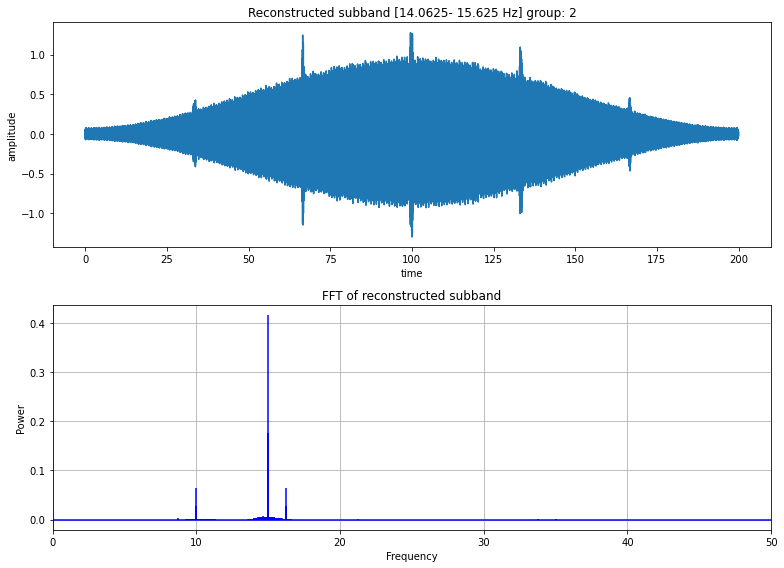

energy of recovered signal: 2498.765631414285
kurtosis of recovered signal: 0.07697907448272812
crest factor of recovered signal: 3.679820552940982
entropy of recovered signal: 9.074702036960797

energy of node coefficients: 2500.4392566783854
kurtosis of node coefficients: 2.957837207197066
crest factor of node coefficients: 2.9174433408657725
entropy of node coefficinets: 5.662016890169955


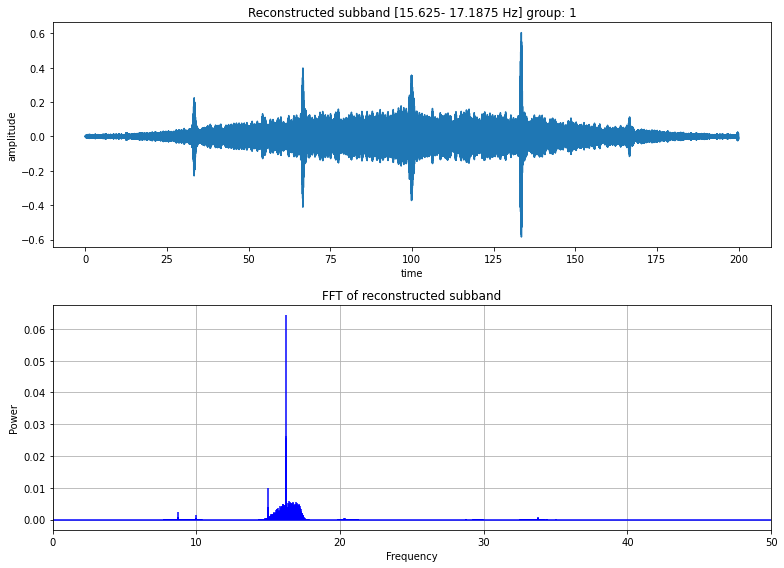

energy of recovered signal: 77.83617027775641
kurtosis of recovered signal: 6.854987582185368
crest factor of recovered signal: 9.685607763443857
entropy of recovered signal: 8.714910792105263

energy of node coefficients: 78.17322923159378
kurtosis of node coefficients: 7.859004288216638
crest factor of node coefficients: 7.052930894614335
entropy of node coefficinets: 5.349727327650386


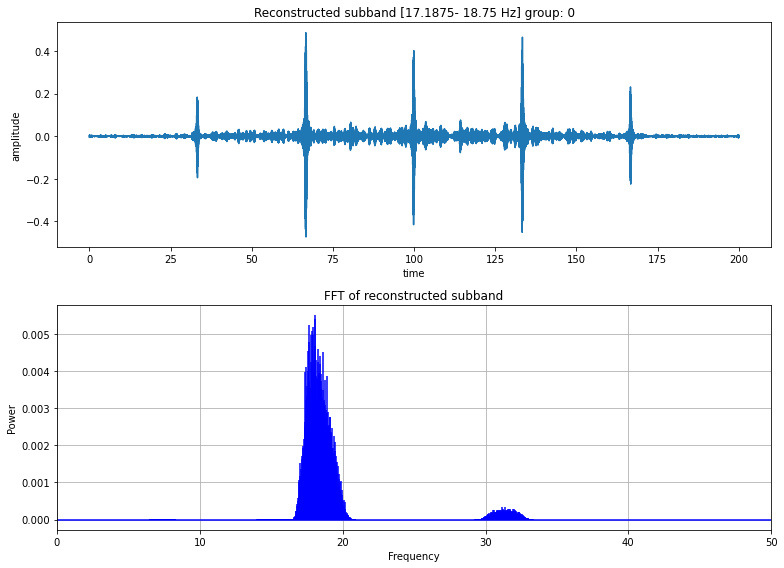

energy of recovered signal: 16.765278917752653
kurtosis of recovered signal: 89.94159812835142
crest factor of recovered signal: 16.805506661858658
entropy of recovered signal: 6.410502655637368

energy of node coefficients: 16.802611222783746
kurtosis of node coefficients: 72.39122983426297
crest factor of node coefficients: 12.34830891099633
entropy of node coefficinets: 3.2161542845866595


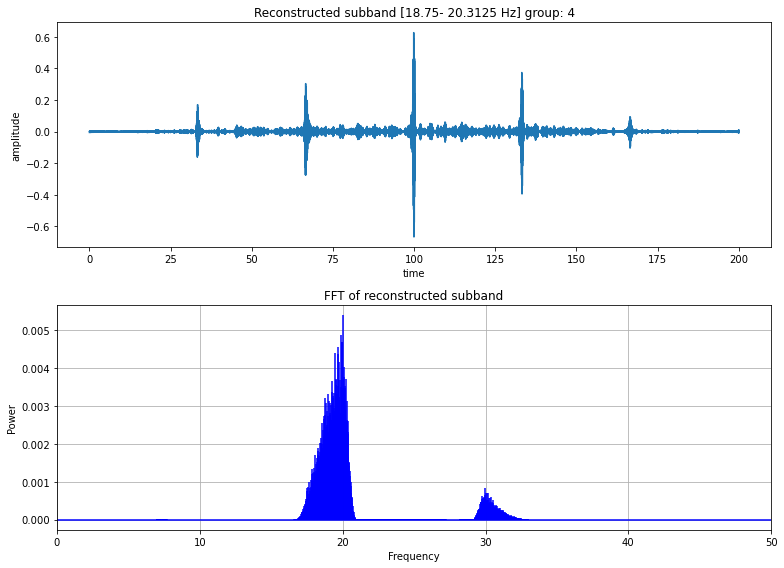

energy of recovered signal: 14.777779985252966
kurtosis of recovered signal: 158.3485842287388
crest factor of recovered signal: 24.56563579692944
entropy of recovered signal: 6.076106053171941

energy of node coefficients: 14.804821054684938
kurtosis of node coefficients: 70.09545888878499
crest factor of node coefficients: 12.432295202935439
entropy of node coefficinets: 3.163129395818813


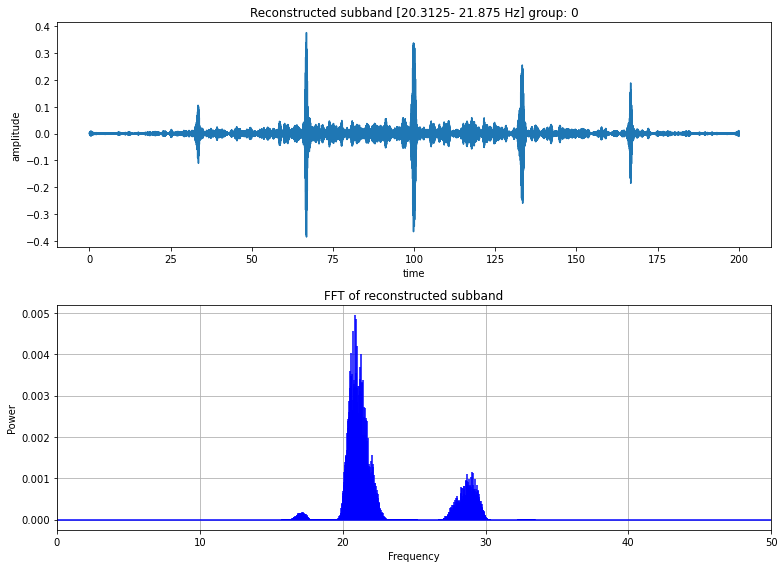

energy of recovered signal: 11.191341414570882
kurtosis of recovered signal: 73.87384394098855
crest factor of recovered signal: 16.287723207661067
entropy of recovered signal: 6.647577932297563

energy of node coefficients: 11.238216024736714
kurtosis of node coefficients: 58.28237665614101
crest factor of node coefficients: 10.710956258665616
entropy of node coefficinets: 3.3203945186310535


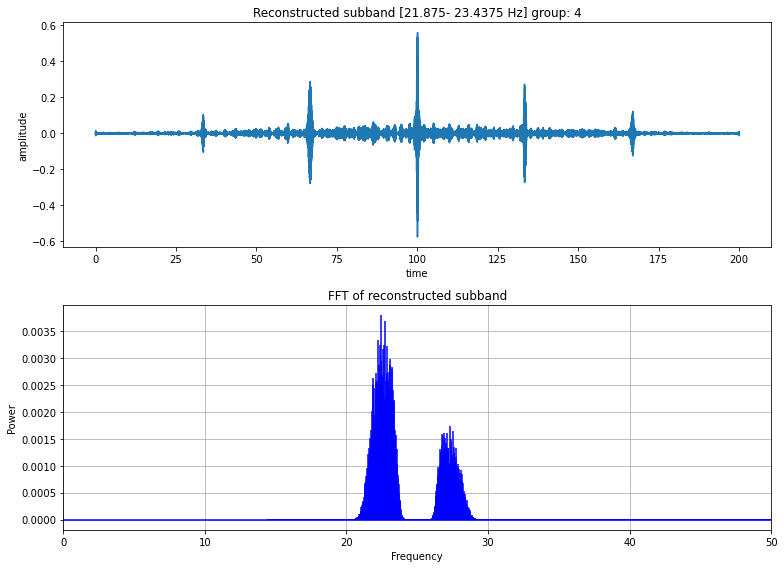

energy of recovered signal: 10.889341245843248
kurtosis of recovered signal: 140.65887359488374
crest factor of recovered signal: 24.673144617878823
entropy of recovered signal: 6.316684781503379

energy of node coefficients: 10.934153546811324
kurtosis of node coefficients: 46.85999225293371
crest factor of node coefficients: 11.097113384402402
entropy of node coefficinets: 3.600960294911026


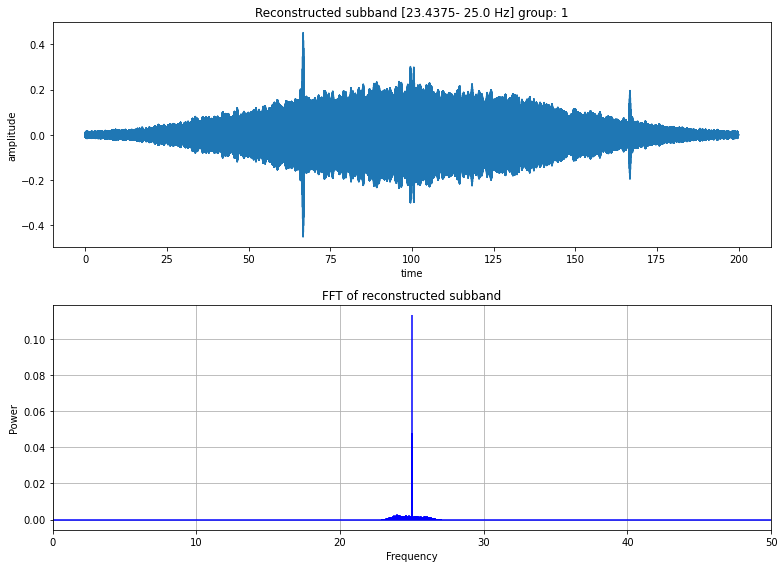

energy of recovered signal: 182.56762119076512
kurtosis of recovered signal: -0.1896699145631784
crest factor of recovered signal: 4.730215404723586
entropy of recovered signal: 9.216132528909998

energy of node coefficients: 182.73329382702877
kurtosis of node coefficients: 2.7935468884724597
crest factor of node coefficients: 3.4882171035832763
entropy of node coefficinets: 5.9122409654999535


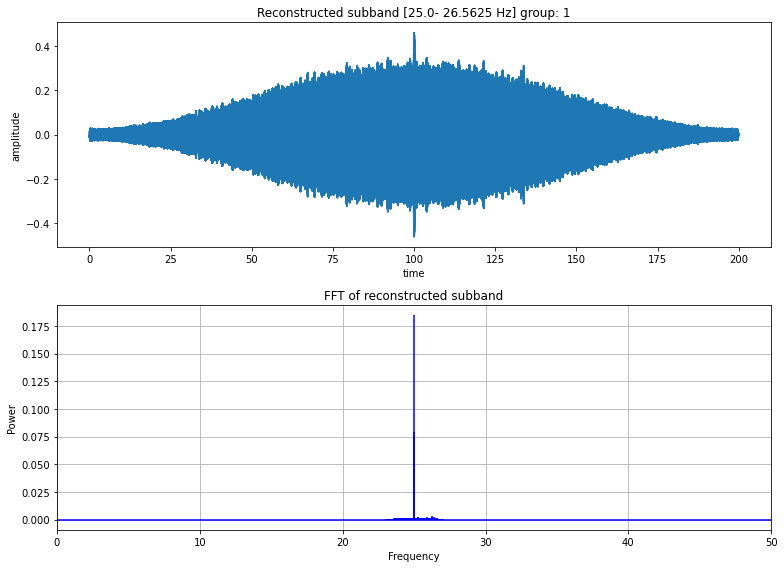

energy of recovered signal: 472.49079143591337
kurtosis of recovered signal: -0.5597408186083896
crest factor of recovered signal: 3.013053903412028
entropy of recovered signal: 9.26588288985881

energy of node coefficients: 472.9134803151024
kurtosis of node coefficients: 1.6142613275333966
crest factor of node coefficients: 2.0978145646460833
entropy of node coefficinets: 5.955672635729314


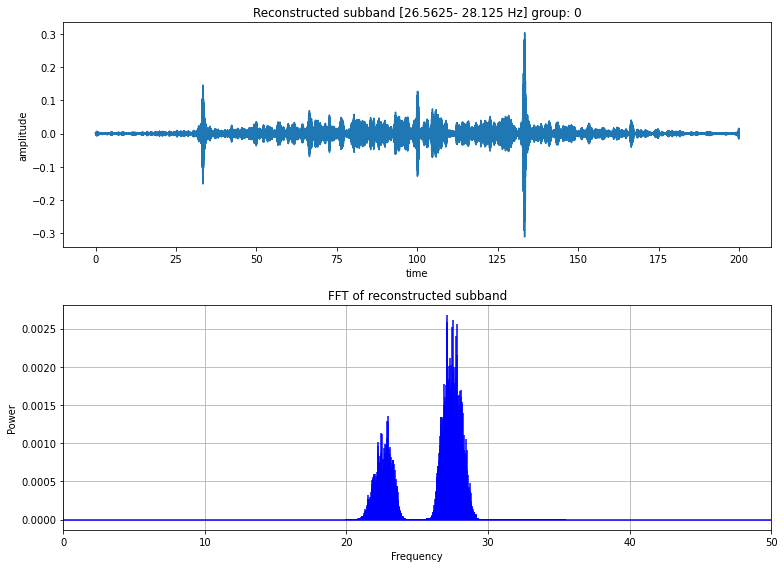

energy of recovered signal: 5.262861554573346
kurtosis of recovered signal: 62.812087562183976
crest factor of recovered signal: 19.145544878118226
entropy of recovered signal: 7.448747964748854

energy of node coefficients: 5.301378994150566
kurtosis of node coefficients: 28.365030685040015
crest factor of node coefficients: 9.746728175213873
entropy of node coefficinets: 4.372749338787702


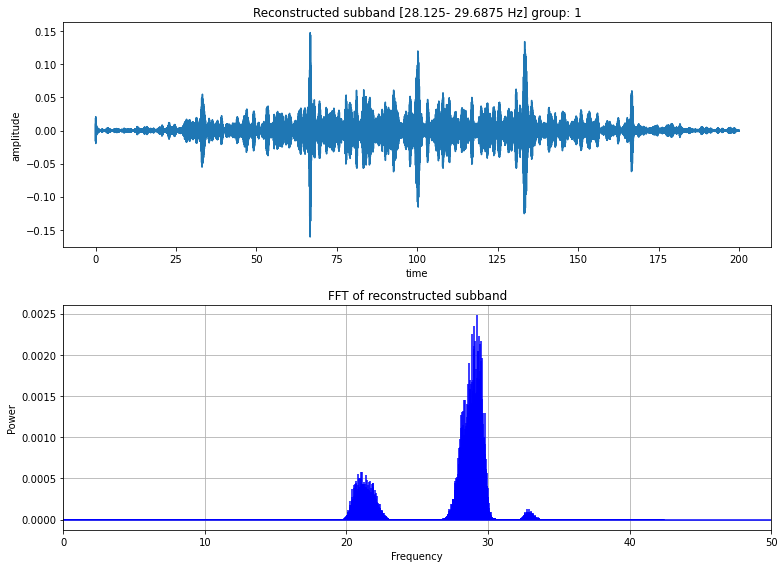

energy of recovered signal: 3.888710242752455
kurtosis of recovered signal: 14.95404603179595
crest factor of recovered signal: 11.544994805079249
entropy of recovered signal: 8.120190090962032

energy of node coefficients: 3.903971193274832
kurtosis of node coefficients: 12.6290503276004
crest factor of node coefficients: 7.325021362215229
entropy of node coefficinets: 4.854482497831196


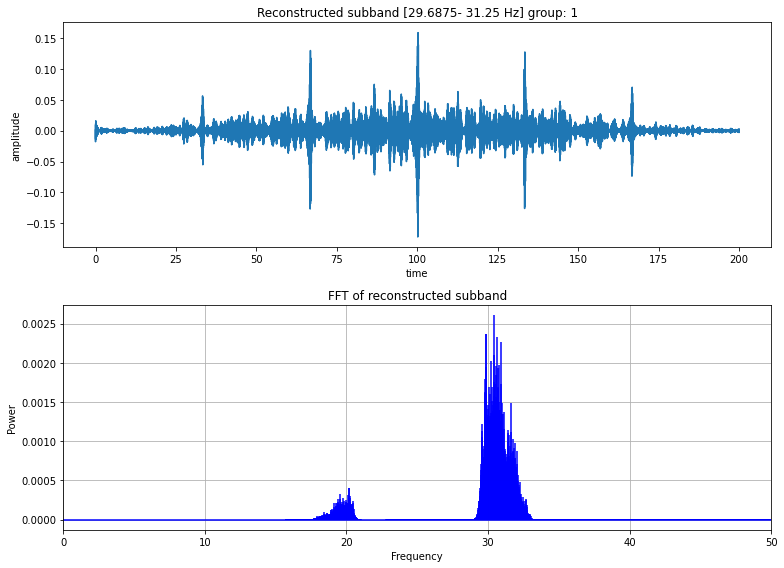

energy of recovered signal: 3.6805966055524046
kurtosis of recovered signal: 17.589010678640005
crest factor of recovered signal: 12.690701518556445
entropy of recovered signal: 8.111624306959936

energy of node coefficients: 3.6993702898877276
kurtosis of node coefficients: 13.167875514505813
crest factor of node coefficients: 7.435712288286348
entropy of node coefficinets: 4.8833420977924415


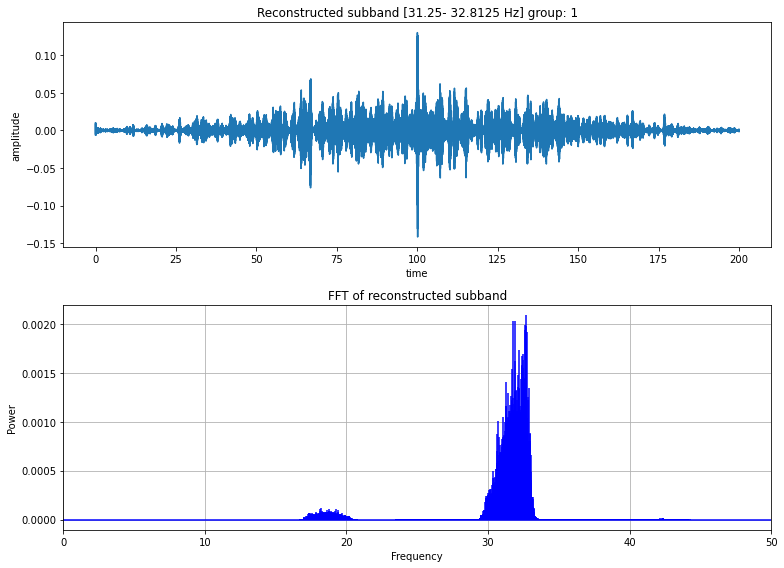

energy of recovered signal: 3.21067136462757
kurtosis of recovered signal: 9.043276710880168
crest factor of recovered signal: 11.200366442020814
entropy of recovered signal: 8.421902750524845

energy of node coefficients: 3.2364509202520835
kurtosis of node coefficients: 6.628655910113378
crest factor of node coefficients: 6.149538184489061
entropy of node coefficinets: 5.205911852469051


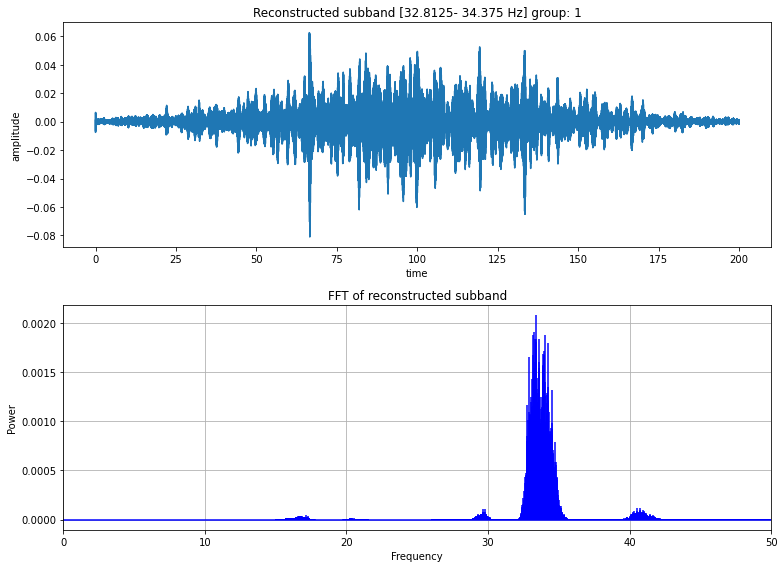

energy of recovered signal: 2.762294690014898
kurtosis of recovered signal: 3.8432958989638175
crest factor of recovered signal: 6.90227448453308
entropy of recovered signal: 8.58680551850379

energy of node coefficients: 2.8003482674919695
kurtosis of node coefficients: 7.541831410545214
crest factor of node coefficients: 5.416160150006012
entropy of node coefficinets: 5.095056995014221


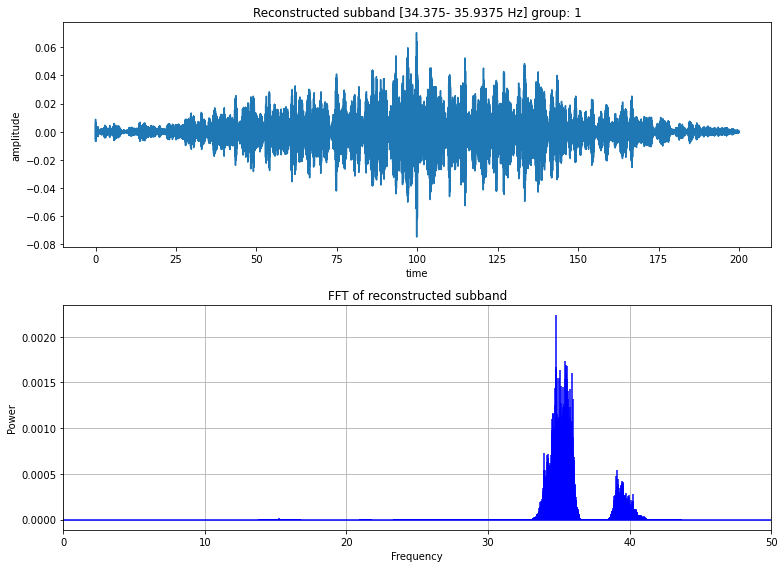

energy of recovered signal: 2.4783542064370128
kurtosis of recovered signal: 2.7916119232929155
crest factor of recovered signal: 6.716680743572643
entropy of recovered signal: 8.710219263322184

energy of node coefficients: 2.4866893732114086
kurtosis of node coefficients: 5.924786315525719
crest factor of node coefficients: 4.7978469329730835
entropy of node coefficinets: 5.217265514933506


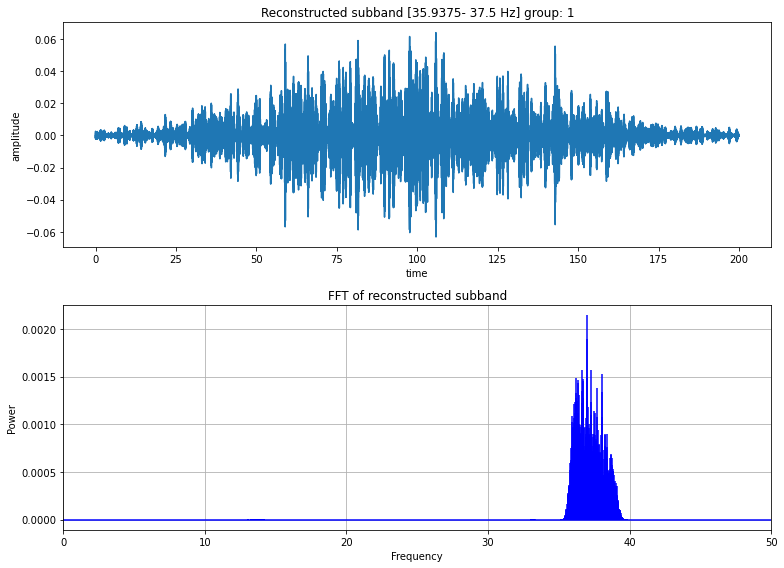

energy of recovered signal: 2.3306862117129064
kurtosis of recovered signal: 4.158318363225846
crest factor of recovered signal: 5.927665098060397
entropy of recovered signal: 8.505928055821025

energy of node coefficients: 2.3335109319097977
kurtosis of node coefficients: 6.245528748835868
crest factor of node coefficients: 4.924297417861553
entropy of node coefficinets: 5.219588537286084


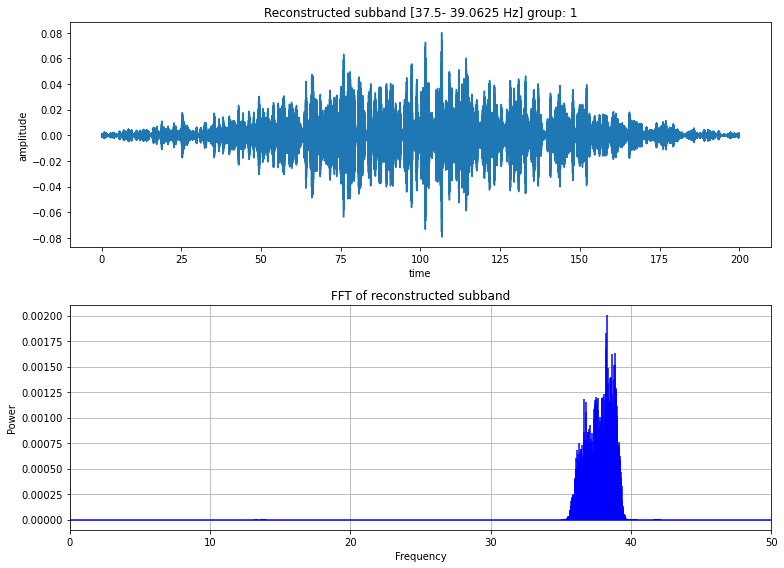

energy of recovered signal: 2.588380711802654
kurtosis of recovered signal: 4.22882012734638
crest factor of recovered signal: 7.046105530554555
entropy of recovered signal: 8.508234956282513

energy of node coefficients: 2.589547400064023
kurtosis of node coefficients: 5.448150636473712
crest factor of node coefficients: 3.8300804612758386
entropy of node coefficinets: 5.2429228724883945


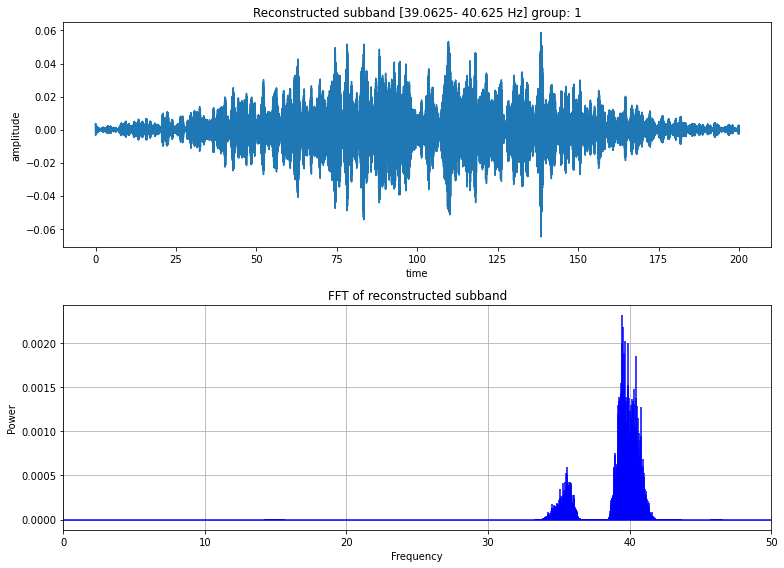

energy of recovered signal: 2.288393355750618
kurtosis of recovered signal: 2.632183583740624
crest factor of recovered signal: 6.07707441099402
entropy of recovered signal: 8.7120526847042

energy of node coefficients: 2.2903617588941887
kurtosis of node coefficients: 6.121980400455139
crest factor of node coefficients: 5.115990791130812
entropy of node coefficinets: 5.237289982793796


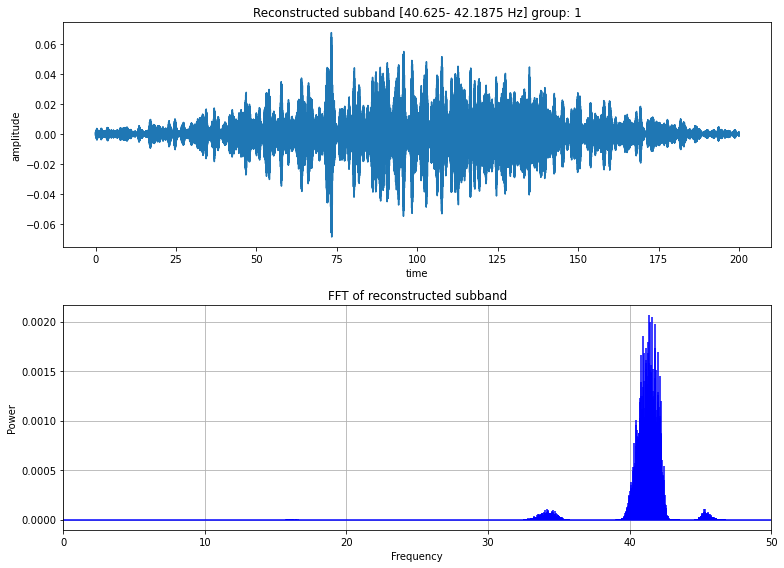

energy of recovered signal: 2.7493935062585977
kurtosis of recovered signal: 2.807140053837994
crest factor of recovered signal: 5.871764274814618
entropy of recovered signal: 8.667820271109555

energy of node coefficients: 2.7525295430654118
kurtosis of node coefficients: 5.356442938698225
crest factor of node coefficients: 4.174133752570877
entropy of node coefficinets: 5.281188128614606


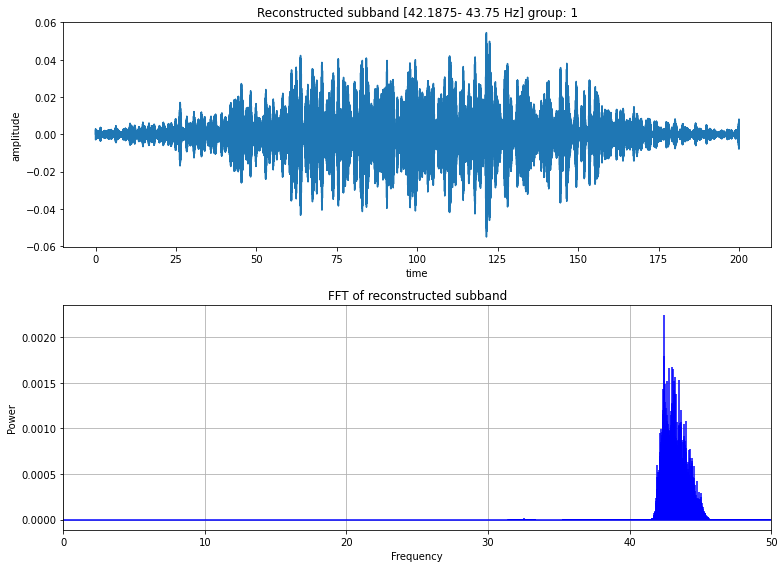

energy of recovered signal: 2.1703607792118715
kurtosis of recovered signal: 2.128174528356179
crest factor of recovered signal: 5.28172458140575
entropy of recovered signal: 8.733838439538419

energy of node coefficients: 2.1783391659232065
kurtosis of node coefficients: 5.544397629408308
crest factor of node coefficients: 4.282923951126952
entropy of node coefficinets: 5.290504884195851


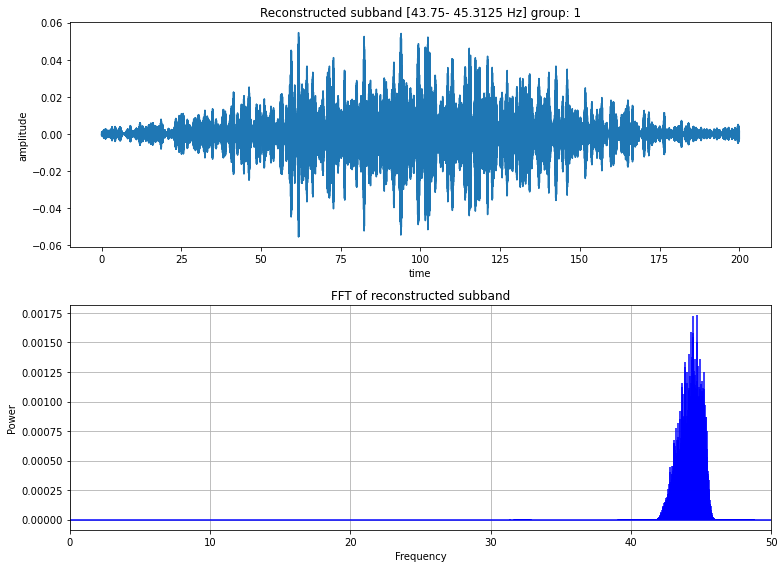

energy of recovered signal: 2.2194679449918953
kurtosis of recovered signal: 3.1582606880554067
crest factor of recovered signal: 5.2819154293079675
entropy of recovered signal: 8.63741004058546

energy of node coefficients: 2.2222952722495926
kurtosis of node coefficients: 5.535164766651803
crest factor of node coefficients: 4.7527832957188885
entropy of node coefficinets: 5.271323452046232


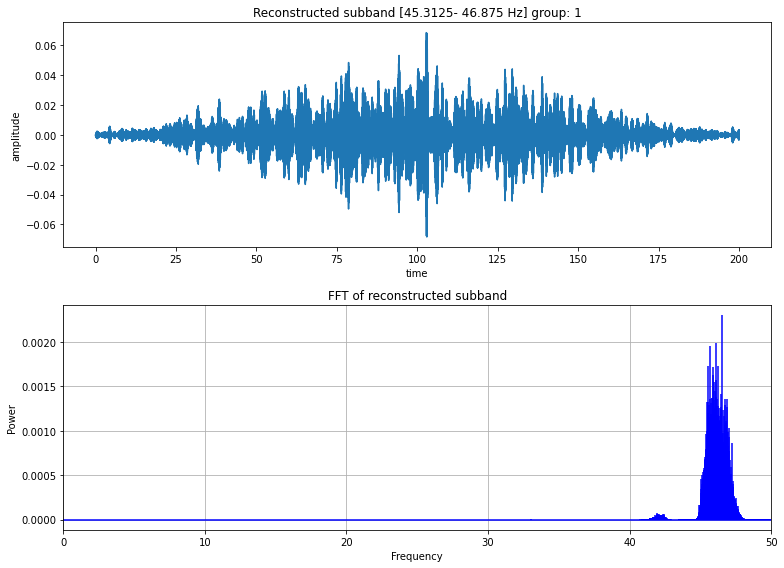

energy of recovered signal: 2.313868215867535
kurtosis of recovered signal: 3.0615908595569117
crest factor of recovered signal: 6.380714763420209
entropy of recovered signal: 8.668882109854446

energy of node coefficients: 2.3160378413825313
kurtosis of node coefficients: 5.585387159722183
crest factor of node coefficients: 4.369363596358265
entropy of node coefficinets: 5.258853416782181


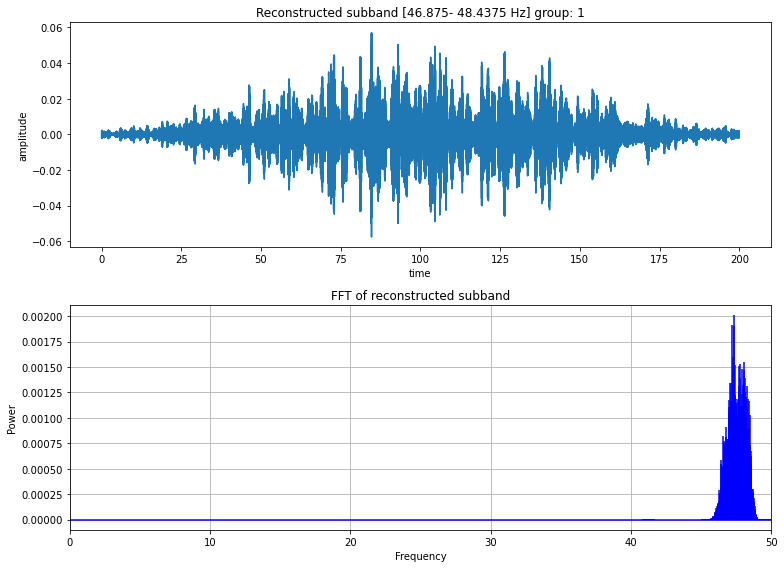

energy of recovered signal: 2.2769300808448345
kurtosis of recovered signal: 2.7135256309283102
crest factor of recovered signal: 5.397929494392283
entropy of recovered signal: 8.675278634271029

energy of node coefficients: 2.2791745875722254
kurtosis of node coefficients: 4.9085984388534305
crest factor of node coefficients: 4.226542589512193
entropy of node coefficinets: 5.32144672242486


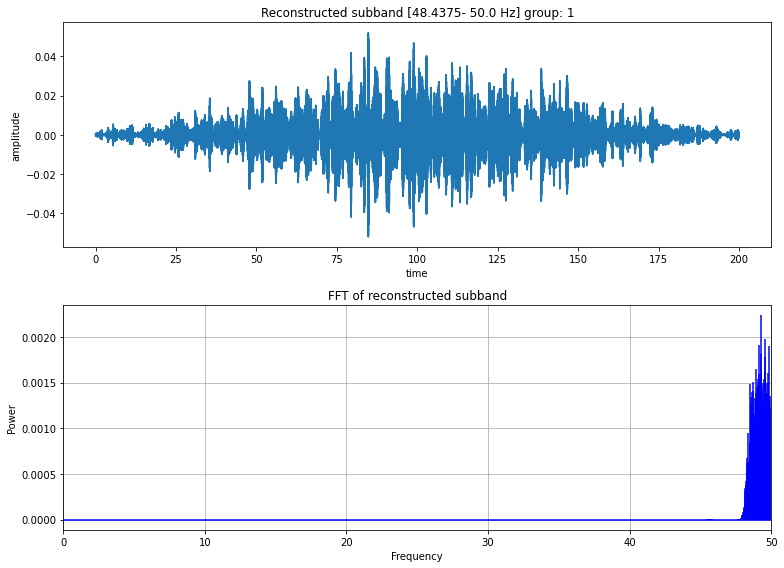

energy of recovered signal: 2.48579521364925
kurtosis of recovered signal: 1.794624735383323
crest factor of recovered signal: 4.678864237194785
entropy of recovered signal: 8.787757464215959

energy of node coefficients: 2.4868156116557376
kurtosis of node coefficients: 4.606142552583805
crest factor of node coefficients: 3.774365334911656
entropy of node coefficinets: 5.352185409732581


array([-0.0056654 ,  0.00411047,  0.13103131, ..., -0.05455422,
       -0.03741695,  0.00484949])

In [15]:
plot_reconstructions(rec, group=labels)

# Appendix

### kurtosis and crest factor calculations
testing kurtosis and crest factor calculations on wavelet packet coefficients and reconstructed waves

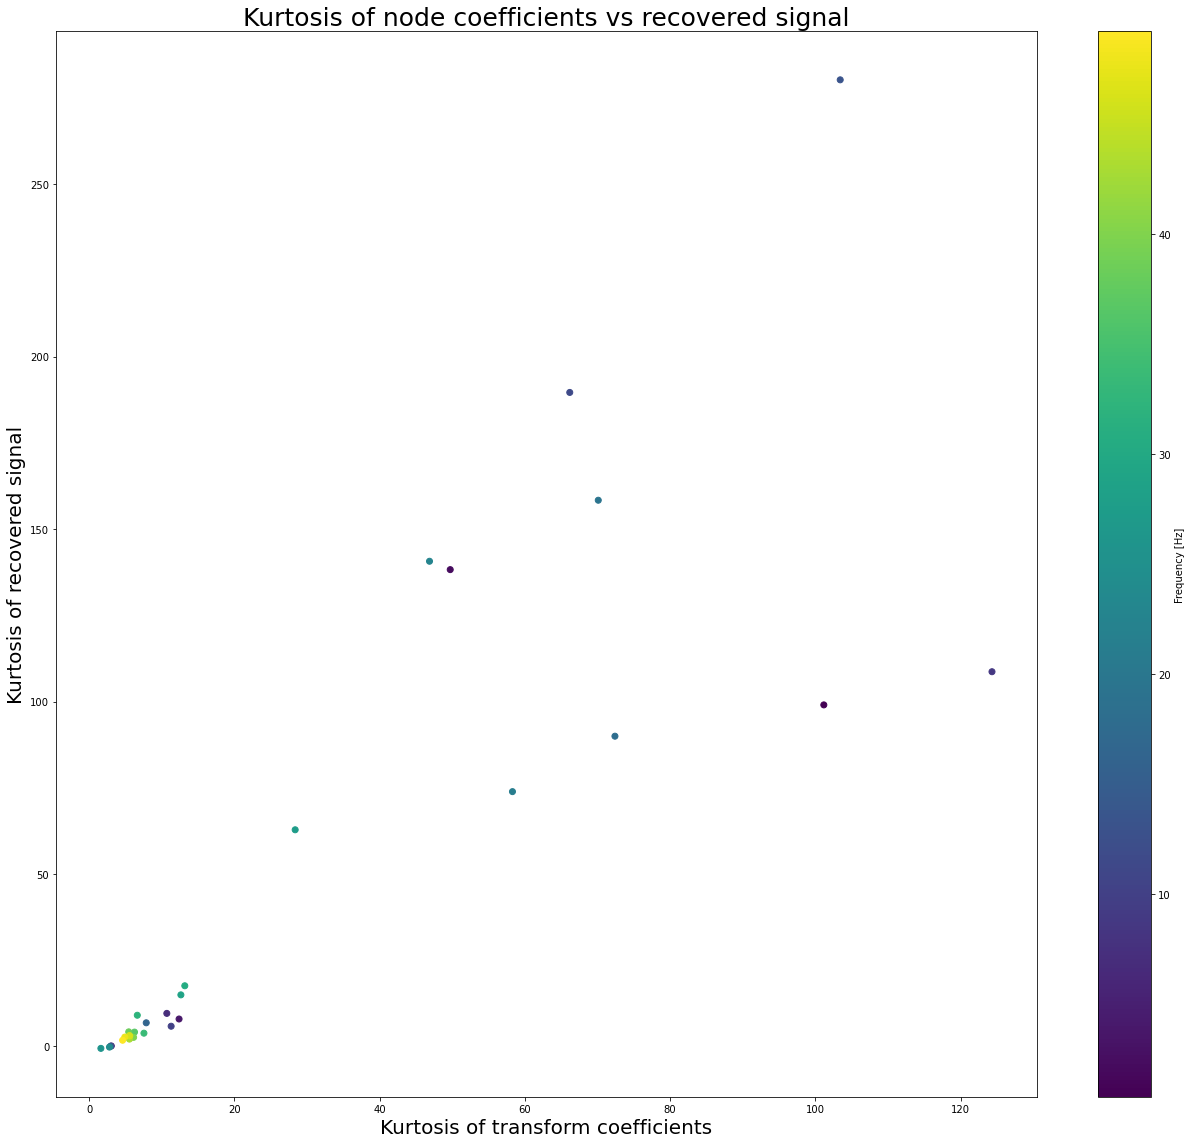

In [16]:
# Calculate frequenciens for plotting
cent_freqs = [
    round(1 / 2 * sum(node.frequency_range), 1)
    for node in tr_obj.get_level(order="freq")
]
cent_freqs = np.array(cent_freqs)
sparse_cent_freqs = [
    cent_freq if id % 1 == 0 else "" for id, cent_freq in enumerate(cent_freqs)
]

# Gather data
coef_kurtosis = [node.kurtosis for node, *_ in rec]
kurtosis = [sc.kurtosis(i) for _, i, *_ in rec]

# plot bar chart
fig, ax = plt.subplots()
width = 0.4

fig.set_size_inches(18, 16)

scatter = ax.scatter(coef_kurtosis, kurtosis, c=cent_freqs)
ax.set_title("Kurtosis of node coefficients vs recovered signal", fontsize=25)
ax.set_xlabel("Kurtosis of transform coefficients", fontsize=20)
ax.set_ylabel("Kurtosis of recovered signal", fontsize=20)

fig.colorbar(scatter, ax=ax, label="Frequency [Hz]")

fig.tight_layout()
plt.show()

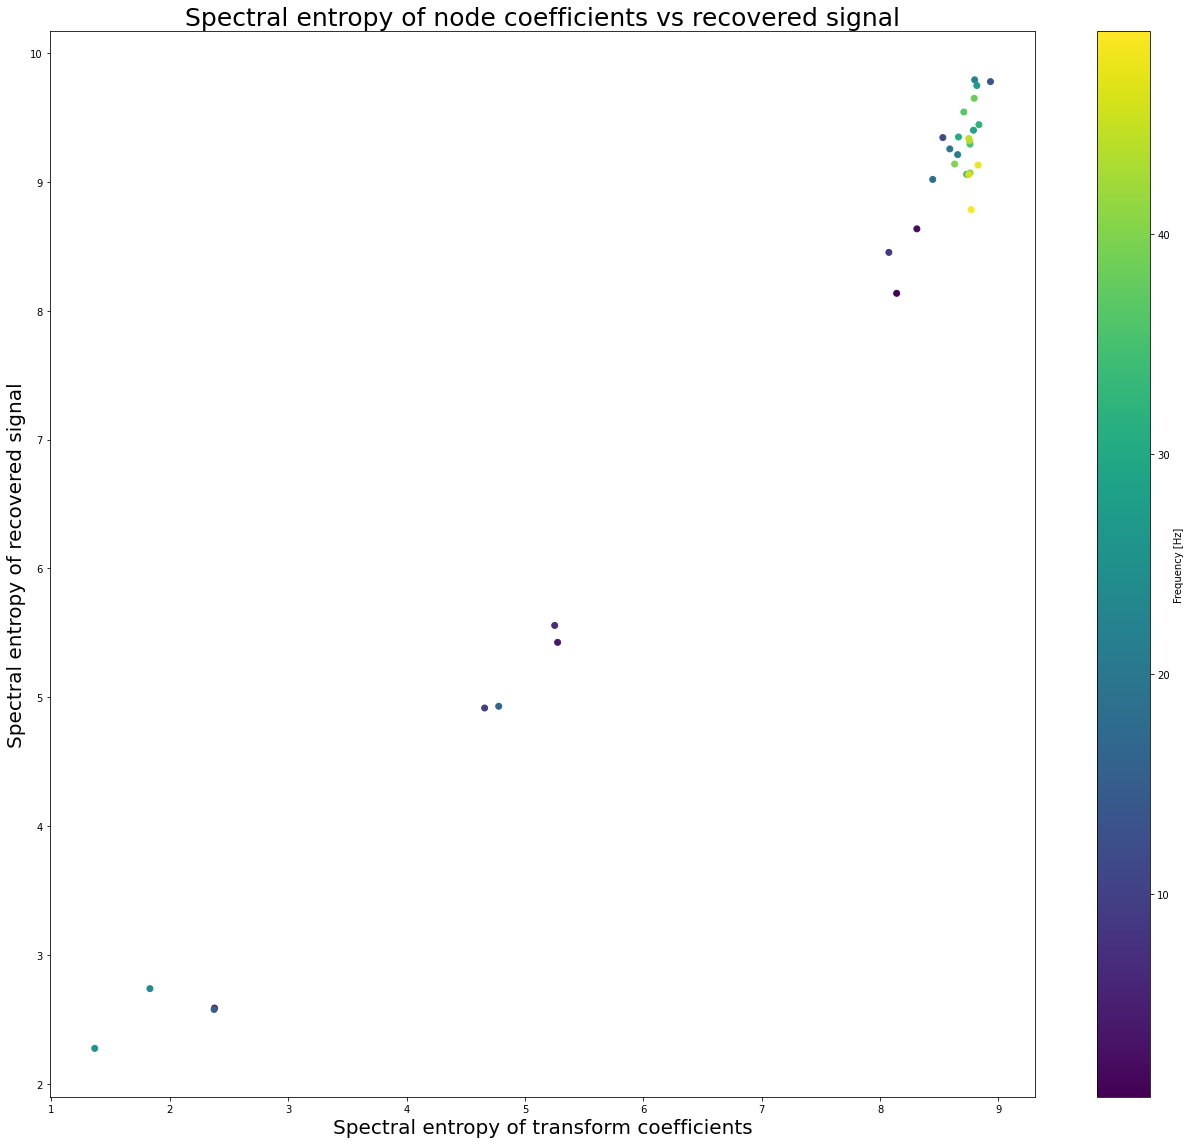

In [17]:
# gather data
coef_spectral_entropy = [node.spectral_entropy for node, *_ in rec]
rec_spectral_entropy = [stats.spectral_entropy(i) for _, i, *_ in rec]

# plot bar chart
fig, ax = plt.subplots()
width = 0.4

fig.set_size_inches(18, 16)

scatter = ax.scatter(coef_spectral_entropy, rec_spectral_entropy, c=cent_freqs)
ax.set_title("Spectral entropy of node coefficients vs recovered signal", fontsize=25)
ax.set_xlabel("Spectral entropy of transform coefficients", fontsize=20)
ax.set_ylabel("Spectral entropy of recovered signal", fontsize=20)

fig.colorbar(scatter, ax=ax, label="Frequency [Hz]")

fig.tight_layout()
plt.show()

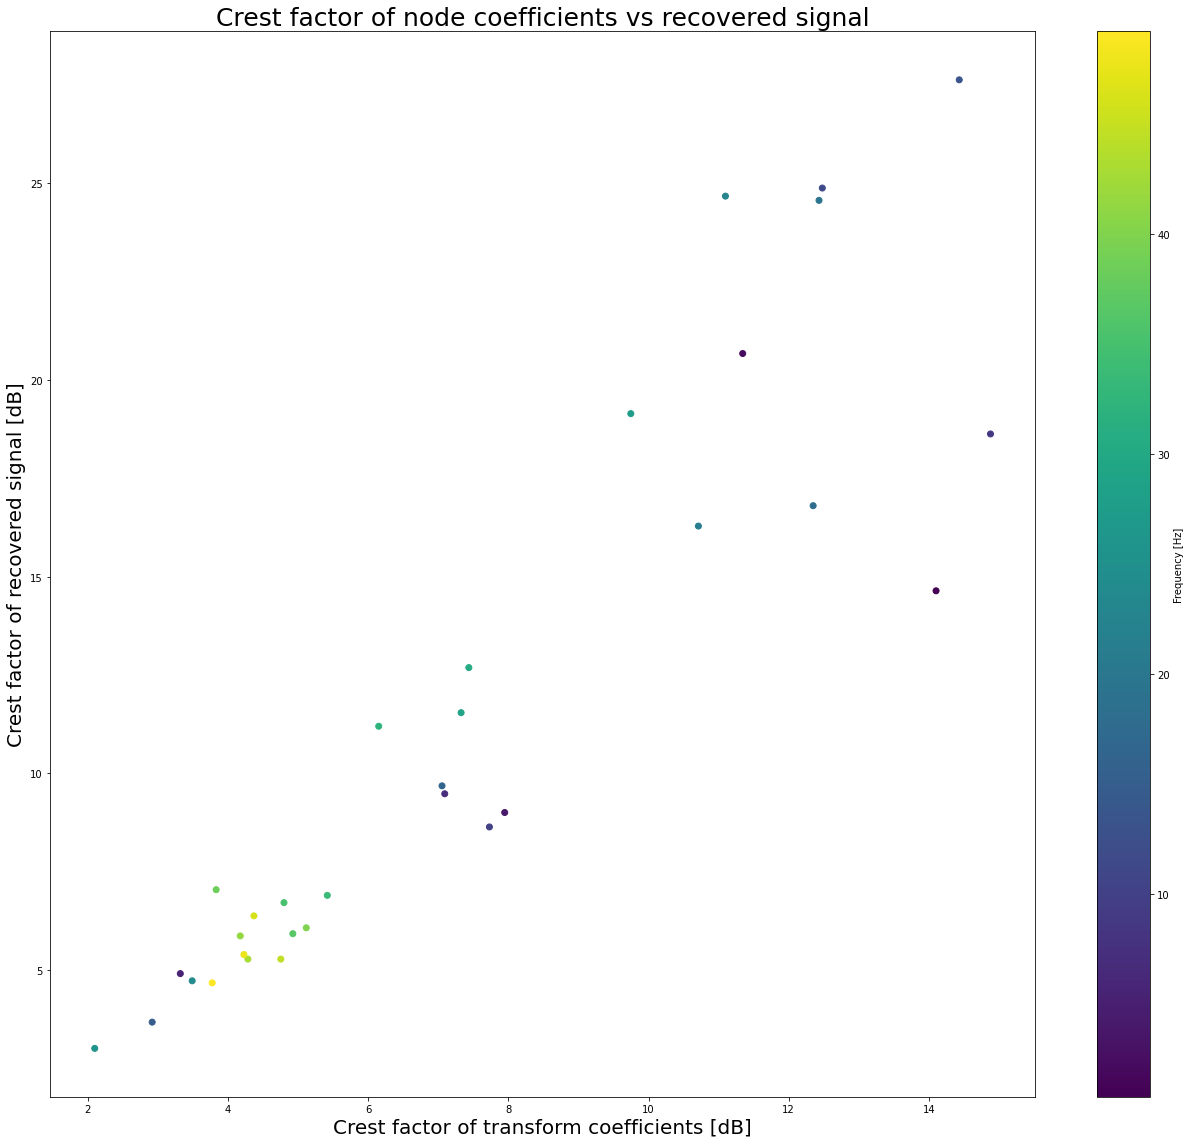

In [18]:
# gather data
coef_crest = [node.crest_factor for node, *_ in rec]
crest = [stats.crest_factor(i) for _, i, *_ in rec]

# plot bar chart
fig, ax = plt.subplots()
width = 0.4

fig.set_size_inches(18, 16)

scatter = ax.scatter(coef_crest, crest, c=cent_freqs)
ax.set_title("Crest factor of node coefficients vs recovered signal", fontsize=25)
ax.set_xlabel("Crest factor of transform coefficients [dB]", fontsize=20)
ax.set_ylabel("Crest factor of recovered signal [dB]", fontsize=20)

fig.colorbar(scatter, ax=ax, label="Frequency [Hz]")

fig.tight_layout()
plt.show()

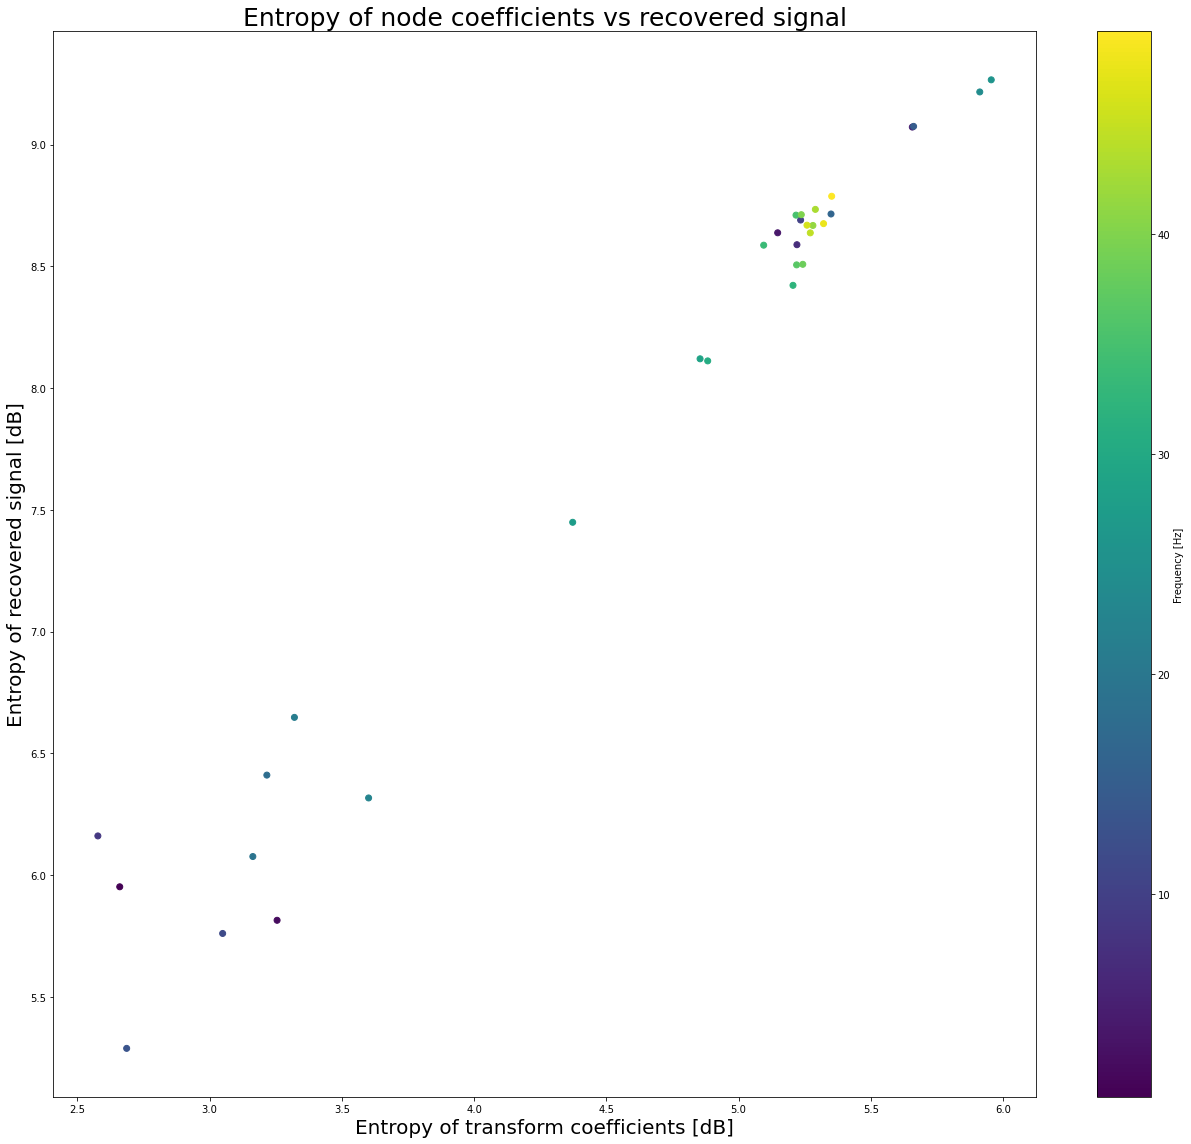

In [19]:
# gather data
coef_entropy = [node.entropy for node, *_ in rec]
entropy = [stats.entropy(i) for _, i, *_ in rec]

# plot bar chart
fig, ax = plt.subplots()
width = 0.4

fig.set_size_inches(18, 16)

scatter = ax.scatter(coef_entropy, entropy, c=cent_freqs)
ax.set_title("Entropy of node coefficients vs recovered signal", fontsize=25)
ax.set_xlabel("Entropy of transform coefficients [dB]", fontsize=20)
ax.set_ylabel("Entropy of recovered signal [dB]", fontsize=20)

fig.colorbar(scatter, ax=ax, label="Frequency [Hz]")

fig.tight_layout()
plt.show()